# 02 — Electorate Turnout, Polling Sections & Vote Validity Breakdown
**Eleição Ordinária Federal 2026 (`ele=6257`) — 1º Turno — Seções (`s`), Eleitorado (`e`) & Votos (`v`)**

This notebook inspects the structural electoral metrics reported by the TSE across all **499,248 polling sections** (`seções eleitorais`) and **158,745,502 registered voters** (`eleitorado apto`):
1. **Structured Audit Tables**: Complete breakdown of Polling Sections (`s`), Electorate & Turnout (`e`), and Vote Categories (`v`: Nominal/Valid, Blank, Regular Null, and Technical Null).
2. **Hierarchical Waterfall / Stacked Composition**: Traces how the 158.75M registered voters divide into Turnout vs Abstention, Valid vs Invalid votes, and candidate blocks.
3. **"The Invisible Electorate" Ranking**: Compares Abstentions (33.47M), Null votes (3.67M), and Blank votes (2.30M) directly against the nominal votes of the presidential candidates.
4. **Polling Section & Invalid Vote Diagnostics**: Detailed view of installed vs non-installed sections (`si` vs `sni`) and the composition of the 5.98M non-valid votes.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data").exists() and (REPO_ROOT.parent / "data").exists():
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data"
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 120
sns.set_theme(style="whitegrid")

latest_path = sorted(DATA_DIR.glob("presidente_br_*.json"))[-1]
with latest_path.open(encoding="utf-8") as fh:
    doc = json.load(fh)

payload = doc["data"]
s = payload["s"]
e = payload["e"]
v = payload["v"]

summary_rows = [
    ("Seções (s)", "Total de Seções (ts)", int(s["ts"]), 100.0),
    ("Seções (s)", "Seções Totalizadas (st)", int(s["st"]), float(s["pstn"].replace(",", "."))),
    ("Seções (s)", "Seções Instaladas (si)", int(s["si"]), float(s["psin"].replace(",", "."))),
    ("Seções (s)", "Seções Não Instaladas (sni)", int(s["sni"]), float(s["psnin"].replace(",", "."))),
    ("Seções (s)", "Seções Apuradas (sa)", int(s["sa"]), float(s["psan"].replace(",", "."))),
    ("Eleitorado (e)", "Total do Eleitorado (te)", int(e["te"]), 100.0),
    ("Eleitorado (e)", "Eleitorado em Seções Instaladas (esi)", int(e["esi"]), float(e["pesin"].replace(",", "."))),
    ("Eleitorado (e)", "Comparecimento (c)", int(e["c"]), float(e["pcn"].replace(",", "."))),
    ("Eleitorado (e)", "Abstenção (a)", int(e["a"]), float(e["pan"].replace(",", "."))),
    ("Votos (v)", "Total de Votos (tv)", int(v["tv"]), 100.0),
    ("Votos (v)", "Votos Válidos / Nominais (vv / vnom)", int(v["vv"]), float(v["pvvcn"].replace(",", "."))),
    ("Votos (v)", "Votos em Branco (vb)", int(v["vb"]), float(v["pvbn"].replace(",", "."))),
    ("Votos (v)", "Total de Votos Nulos (tvn)", int(v["tvn"]), float(v["ptvnn"].replace(",", "."))),
    ("Votos (v)", "  ├─ Votos Nulos Comuns (vn)", int(v["vn"]), float(v["pvnn"].replace(",", "."))),
    ("Votos (v)", "  └─ Votos Nulos Técnicos (vnt)", int(v["vnt"]), float(v["pvntn"].replace(",", "."))),
]

df_summary = pd.DataFrame(summary_rows, columns=["Category", "Metric", "Count", "Percentage (%)"])
df_summary["Formatted Count"] = df_summary["Count"].map(lambda x: f"{x:,d}")
df_summary[["Category", "Metric", "Formatted Count", "Percentage (%)"]]

,Category,Metric,Formatted Count,Percentage (%)
0,Seções (s),Total de Seções (ts),"499,248",100.000000
1,Seções (s),Seções Totalizadas (st),"499,248",100.000000
2,Seções (s),Seções Instaladas (si),"499,207",99.991788
3,Seções (s),Seções Não Instaladas (sni),41,0.008212
4,Seções (s),Seções Apuradas (sa),"499,207",100.000000
5,Eleitorado (e),Total do Eleitorado (te),"158,745,502",100.000000
6,Eleitorado (e),Eleitorado em Seções Instaladas (esi),"158,745,079",99.999734
7,Eleitorado (e),Comparecimento (c),"125,275,835",78.916358
8,Eleitorado (e),Abstenção (a),"33,469,244",21.083642
9,Votos (v),Total de Votos (tv),"125,275,835",100.000000


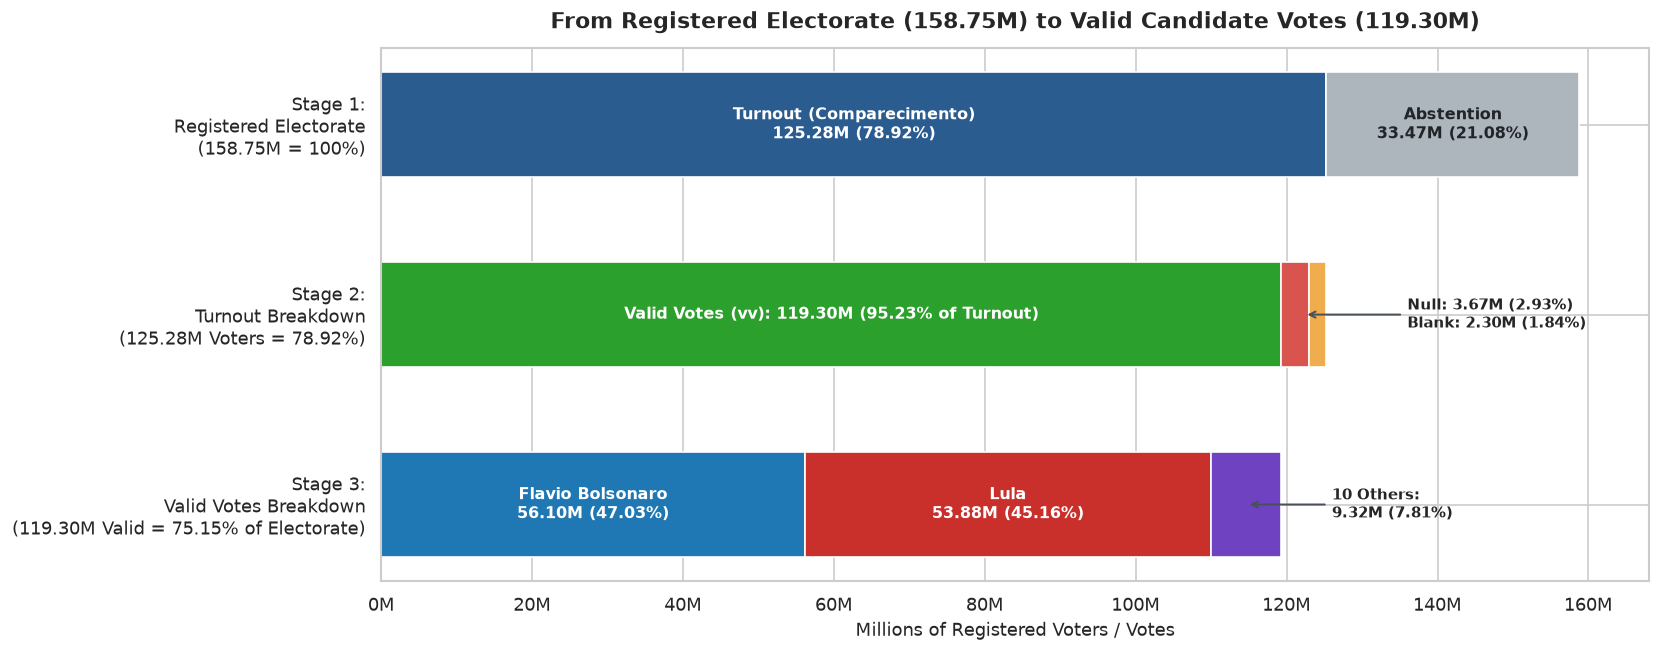

In [2]:
# Graph 1: Multi-Stage Horizontal Composition of the Brazilian Electorate (158.75M Voters)
te = int(e["te"])
comp = int(e["c"])
abst = int(e["a"]) + int(e["esni"])  # include 423 voters from non-installed sections for exact total
vv = int(v["vv"])
tvn = int(v["tvn"])
vb = int(v["vb"])

# Candidate votes for stage 3
cand_map = {}
for carg in payload["carg"]:
    for agr in carg["agr"]:
        for par in agr["par"]:
            for c in par["cand"]:
                cand_map[c["nmu"]] = int(c["vap"])

flavio_v = cand_map["FLAVIO BOLSONARO"]
lula_v = cand_map["LULA"]
others_v = vv - flavio_v - lula_v

fig, ax = plt.subplots(figsize=(14, 5.6))

stages = [
    "Stage 1:\nRegistered Electorate\n(158.75M = 100%)",
    "Stage 2:\nTurnout Breakdown\n(125.28M Voters = 78.92%)",
    "Stage 3:\nValid Votes Breakdown\n(119.30M Valid = 75.15% of Electorate)",
]

# Stage 1: Turnout + Abstention
ax.barh(stages[0], comp / 1e6, color="#2b5c8f", edgecolor="white", height=0.55)
ax.barh(stages[0], abst / 1e6, left=comp / 1e6, color="#adb5bd", edgecolor="white", height=0.55)
ax.text(comp / 2e6, 0, f"Turnout (Comparecimento)\n{comp/1e6:.2f}M ({comp/te*100:.2f}%)", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
ax.text((comp + abst / 2) / 1e6, 0, f"Abstention\n{abst/1e6:.2f}M ({abst/te*100:.2f}%)", ha="center", va="center", color="#212529", fontweight="bold", fontsize=9.5)

# Stage 2: Valid + Null + Blank
ax.barh(stages[1], vv / 1e6, color="#2ca02c", edgecolor="white", height=0.55)
ax.barh(stages[1], tvn / 1e6, left=vv / 1e6, color="#d9534f", edgecolor="white", height=0.55)
ax.barh(stages[1], vb / 1e6, left=(vv + tvn) / 1e6, color="#f0ad4e", edgecolor="white", height=0.55)
ax.text(vv / 2e6, 1, f"Valid Votes (vv): {vv/1e6:.2f}M (95.23% of Turnout)", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
ax.annotate(f"Null: {tvn/1e6:.2f}M (2.93%)\nBlank: {vb/1e6:.2f}M (1.84%)",
            xy=((vv + (tvn + vb) / 2) / 1e6, 1), xytext=(136, 1),
            arrowprops={"arrowstyle": "->", "color": "#495057", "lw": 1.2},
            va="center", fontsize=9, fontweight="bold")

# Stage 3: Flavio + Lula + 10 Others
ax.barh(stages[2], flavio_v / 1e6, color="#1f77b4", edgecolor="white", height=0.55)
ax.barh(stages[2], lula_v / 1e6, left=flavio_v / 1e6, color="#c9302c", edgecolor="white", height=0.55)
ax.barh(stages[2], others_v / 1e6, left=(flavio_v + lula_v) / 1e6, color="#6f42c1", edgecolor="white", height=0.55)
ax.text(flavio_v / 2e6, 2, f"Flavio Bolsonaro\n{flavio_v/1e6:.2f}M (47.03%)", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
ax.text((flavio_v + lula_v / 2) / 1e6, 2, f"Lula\n{lula_v/1e6:.2f}M (45.16%)", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
ax.annotate(f"10 Others:\n{others_v/1e6:.2f}M (7.81%)",
            xy=((flavio_v + lula_v + others_v / 2) / 1e6, 2), xytext=(126, 2),
            arrowprops={"arrowstyle": "->", "color": "#495057", "lw": 1.2},
            va="center", fontsize=9, fontweight="bold")

ax.invert_yaxis()
ax.set_xlim(0, 168)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))
ax.set_xlabel("Millions of Registered Voters / Votes", fontsize=10.5)
ax.set_title("From Registered Electorate (158.75M) to Valid Candidate Votes (119.30M)", fontsize=13, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()

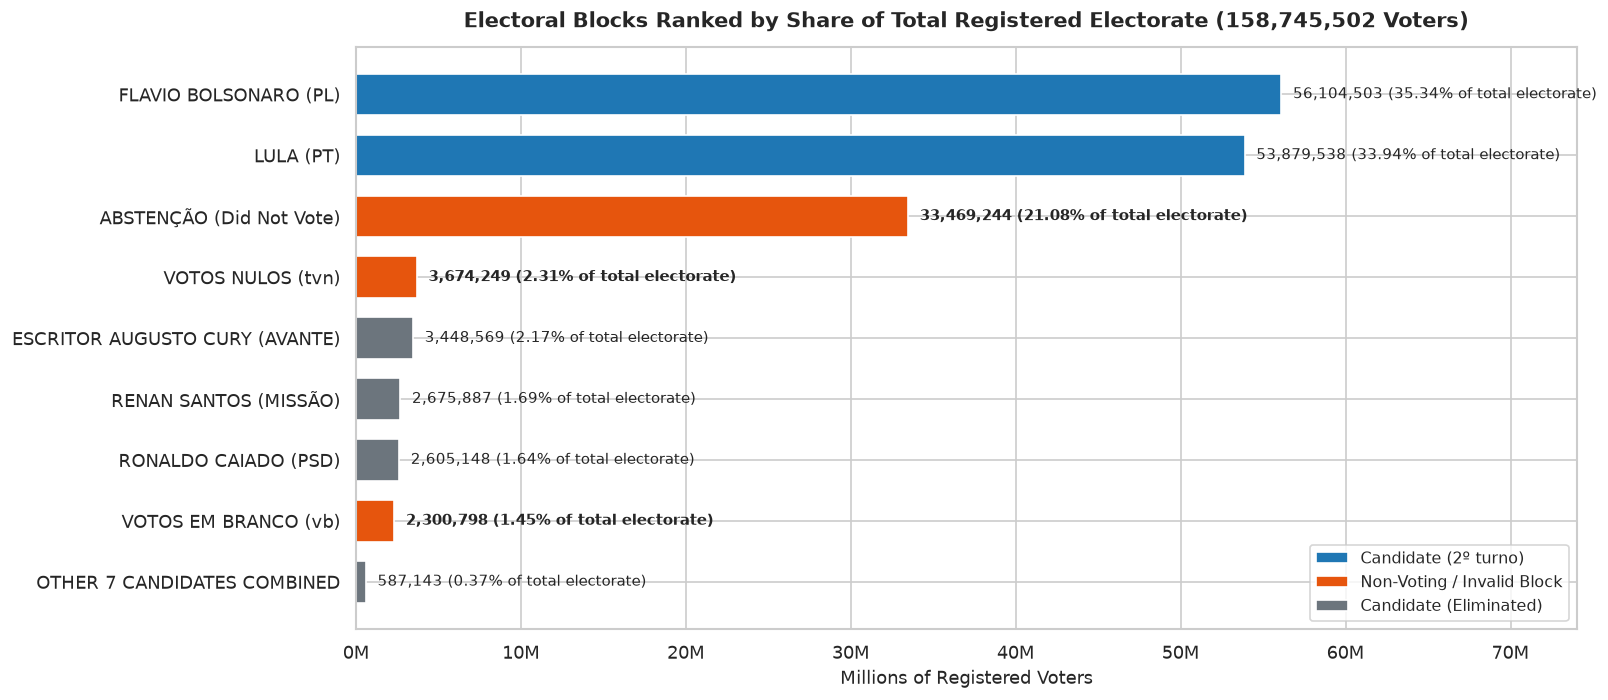

In [3]:
# Graph 2: Comparing "Non-Valid" Electoral Blocks (Abstention, Null, Blank) vs Leading Candidates
blocks = [
    ("FLAVIO BOLSONARO (PL)", flavio_v, "Candidate (2º turno)"),
    ("LULA (PT)", lula_v, "Candidate (2º turno)"),
    ("ABSTENÇÃO (Did Not Vote)", int(e["a"]), "Non-Voting / Invalid Block"),
    ("VOTOS NULOS (tvn)", tvn, "Non-Voting / Invalid Block"),
    ("ESCRITOR AUGUSTO CURY (AVANTE)", cand_map["ESCRITOR AUGUSTO CURY"], "Candidate (Eliminated)"),
    ("RENAN SANTOS (MISSÃO)", cand_map["RENAN SANTOS"], "Candidate (Eliminated)"),
    ("RONALDO CAIADO (PSD)", cand_map["RONALDO CAIADO"], "Candidate (Eliminated)"),
    ("VOTOS EM BRANCO (vb)", vb, "Non-Voting / Invalid Block"),
    ("OTHER 7 CANDIDATES COMBINED", others_v - cand_map["ESCRITOR AUGUSTO CURY"] - cand_map["RENAN SANTOS"] - cand_map["RONALDO CAIADO"], "Candidate (Eliminated)"),
]
df_blocks = pd.DataFrame(blocks, columns=["Block", "Count", "Type"]).sort_values("Count", ascending=True)
df_blocks["Pct_of_Electorate"] = df_blocks["Count"] / te * 100

palette_map = {
    "Candidate (2º turno)": "#1f77b4",
    "Non-Voting / Invalid Block": "#e6550d",
    "Candidate (Eliminated)": "#6c757d",
}
bar_colors = [palette_map[t] for t in df_blocks["Type"]]

fig, ax = plt.subplots(figsize=(13.5, 6))
bars = ax.barh(df_blocks["Block"], df_blocks["Count"] / 1e6, color=bar_colors, edgecolor="white", height=0.68)

for bar, (_, row) in zip(bars, df_blocks.iterrows()):
    w = bar.get_width()
    ax.text(
        w + 0.7, bar.get_y() + bar.get_height() / 2,
        f"{row['Count']:,.0f} ({row['Pct_of_Electorate']:.2f}% of total electorate)",
        va="center", fontsize=9,
        fontweight="bold" if row["Type"] == "Non-Voting / Invalid Block" else "normal"
    )

from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=c, label=lbl) for lbl, c in palette_map.items()]
ax.legend(handles=legend_handles, loc="lower right", frameon=True, fontsize=9.5)
ax.set_xlim(0, 74)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))
ax.set_xlabel("Millions of Registered Voters", fontsize=10.5)
ax.set_title("Electoral Blocks Ranked by Share of Total Registered Electorate (158,745,502 Voters)", fontsize=12.5, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()

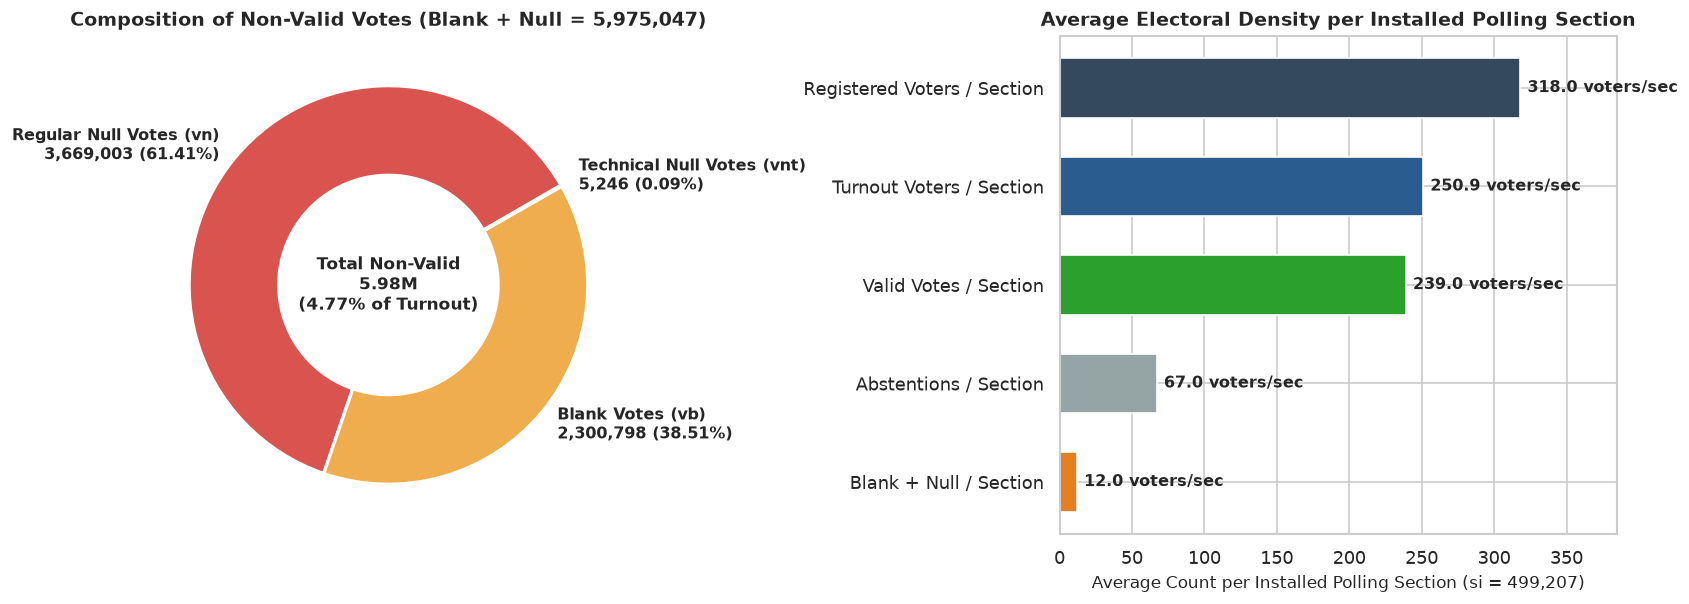

In [4]:
# Graph 3: Invalid Votes Breakdown & Polling Section Operational Metrics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Left: Invalid votes composition (Blank vs Regular Null vs Technical Null)
invalid_labels = [
    f"Regular Null Votes (vn)\n{int(v['vn']):,d} (61.41%)",
    f"Blank Votes (vb)\n{int(v['vb']):,d} (38.51%)",
    f"Technical Null Votes (vnt)\n{int(v['vnt']):,d} (0.09%)",
]
invalid_counts = [int(v["vn"]), int(v["vb"]), int(v["vnt"])]
wedges, _ = ax1.pie(
    invalid_counts,
    labels=invalid_labels,
    colors=["#d9534f", "#f0ad4e", "#5bc0de"],
    startangle=30,
    wedgeprops={"width": 0.45, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 9.5, "fontweight": "bold"},
)
ax1.text(0, 0, f"Total Non-Valid\n{sum(invalid_counts)/1e6:.2f}M\n(4.77% of Turnout)",
         ha="center", va="center", fontsize=10, fontweight="bold")
ax1.set_title("Composition of Non-Valid Votes (Blank + Null = 5,975,047)", fontsize=11.5, fontweight="bold")

# Right: Average Voters per Section (Installed vs Totalized)
sec_installed = int(s["si"])
avg_registered = int(e["esi"]) / sec_installed
avg_turnout = int(e["c"]) / sec_installed
avg_valid = int(v["vv"]) / sec_installed
avg_abstention = int(e["a"]) / sec_installed
avg_invalid = (int(v["vb"]) + int(v["tvn"])) / sec_installed

sec_metrics = [
    ("Registered Voters / Section", avg_registered, "#34495e"),
    ("Turnout Voters / Section", avg_turnout, "#2b5c8f"),
    ("Valid Votes / Section", avg_valid, "#2ca02c"),
    ("Abstentions / Section", avg_abstention, "#95a5a6"),
    ("Blank + Null / Section", avg_invalid, "#e67e22"),
]
m_labels = [m[0] for m in sec_metrics][::-1]
m_vals = [m[1] for m in sec_metrics][::-1]
m_cols = [m[2] for m in sec_metrics][::-1]

bars = ax2.barh(m_labels, m_vals, color=m_cols, height=0.6)
for bar, val in zip(bars, m_vals):
    ax2.text(val + 5, bar.get_y() + bar.get_height() / 2, f"{val:.1f} voters/sec", va="center", fontsize=9.5, fontweight="bold")

ax2.set_xlim(0, 385)
ax2.set_xlabel("Average Count per Installed Polling Section (si = 499,207)", fontsize=10)
ax2.set_title("Average Electoral Density per Installed Polling Section", fontsize=11.5, fontweight="bold")

plt.tight_layout()
plt.show()